# Model memory result

East River: **observed** vs **control** (single bucket) vs **deep store** (threshold shallow store + 2-yr deep store).
Both models were calibrated on the same objective, with no low-flow or memory term.
Tuolumne axes are placeholders for now.

Set `MODEL_SET` in the setup cell to choose the East model pair:
- `"current"`: control = single bucket, deep store = threshold shallow + 2-yr deep store, both calibrated on the same objective
  (`utils/singlebasin_calibration/east_export_final_daily.py`; emulator on SUMMA recharge).
- `"M1"`: the Oct 14 overnight SUMMA runs, old control **M0** (HRU aquifers only) vs **M1** (HRU aquifers + nonlinear
  single-basin deep store), same objective, aquifer and routing parameters only (`deepstore_dev/overnight/summa_daily_M*_full.csv`).
- `"slowroute"`: same control as `"current"`; deep store with τ_s 35 d, S_th 0.05 m and routing scale ~1.6 d instead of
  0.57 d (objective 1.213 vs 1.278, within 3% of the grid best; `east_deepstore_routing_grid.py`).
- `"slowroute_nodeep"`: baseline with the same slow-routing parameters and no deep store: each HRU aquifer is a linear bucket
  (τ_s 35 d) that releases everything to the stream, with no leak and no threshold (`east_slowroute_ablation.py`). The metrics
  table also has a version where the leak goes straight to the stream.

- `"joint"`: the Nov 2 joint fit (`east_memory_joint2.py`, variability-only). Control = bucket refit, no store; deep store =
  surface-runoff capture (42% of surface runoff into a ~2-reservoir cascade, τ ≈ 200 d each, ~70 mm). Both arms fitted to the
  same objective: paper objective (WY1993–2002) + summer and winter recession + fall low-flow level + peak-adjusted lag-1
  memory + year-to-year spread of the fall minimum. Unlike the sets above, memory IS a calibration target here, so the
  lag-1 bar is fitted, not emergent; lags 2–5 and the raw ACF are not targeted. Series:
  `utils/singlebasin_calibration/east_export_joint3_daily.py` (emulator on SUMMA recharge).

Figure files get the set name as a suffix.

In [1]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.colors as mc
from pathlib import Path
from scipy.stats import spearmanr

SCRATCH = Path("/scratch/dlhogan/ess-project-data")
EAST_CSV = SCRATCH/"domain_East_River_distributed_elevAspect/simulations/store_memory_sandbox/East/deepstore_dev/stageB/east_final_models_daily.csv"
FIG_DIR = Path("/home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro/ess-project/figures/draft")

MODEL_SET = "joint"        # "current", "M1", "slowroute", "slowroute_nodeep" or "joint"
JOINT_CSV = EAST_CSV.parent/"east_joint3_models_daily.csv"
OVERNIGHT = SCRATCH/"domain_East_River_distributed_elevAspect/simulations/store_memory_sandbox/East/deepstore_dev/overnight"

EAST_COLOR, TUOLUMNE_COLOR = "#0072B2", "#D55E00"
def shade(c, a):
    """blend toward white (a > 0) or black (a < 0)"""
    r = np.array(mc.to_rgb(c)); return tuple(r + (1 - r)*a if a >= 0 else r*(1 + a))

LABELS = ["observed", "control", "deep store"]
LINE_COLORS = [shade(EAST_COLOR, a) for a in (-0.45, 0.10, 0.45)]
BAR_COLORS  = [shade(EAST_COLOR, a) for a in (-0.45, 0.20, 0.68)]
LINE_STYLES = ["-", "--", "-"]
LINE_WIDTHS = [2.4, 1.8, 2.0]
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False})

east = pd.read_csv(EAST_CSV, index_col="date", parse_dates=True)
if MODEL_SET == "current":
    EAST = {"observed": east["obs"], "control": east["control"], "deep store": east["treatment"]}
    NAMES = {"observed": "observed", "control": "control", "deep store": "deep store"}
elif MODEL_SET == "slowroute":
    EAST = {"observed": east["obs"], "control": east["control"], "deep store": east["treatment_slowroute"]}
    NAMES = {"observed": "observed", "control": "control", "deep store": "deep store (slow routing)"}
elif MODEL_SET == "slowroute_nodeep":
    EAST = {"observed": east["obs"], "control": east["slowroute_noleak"], "deep store": east["treatment_slowroute"]}
    NAMES = {"observed": "observed", "control": "baseline (no deep store)", "deep store": "deep store (slow routing)"}
elif MODEL_SET == "joint":
    joint = pd.read_csv(JOINT_CSV, index_col="date", parse_dates=True)["1981-10-01":"2025-09-30"]
    EAST = {"observed": east["obs"], "control": joint["control_refit"], "deep store": joint["sr_capture_refit"]}
    NAMES = {"observed": "observed", "control": "control (no store)", "deep store": "deep store (surface-runoff capture)"}
elif MODEL_SET == "M1":
    read = lambda f: pd.read_csv(OVERNIGHT/f, index_col=0, parse_dates=True)["q_cms"]["1981-10-01":"2025-09-30"]
    EAST = {"observed": east["obs"], "control": read("summa_daily_M0_full.csv"), "deep store": read("summa_daily_M1_full.csv")}
    NAMES = {"observed": "observed", "control": "control (M0)", "deep store": "deep store (M1)"}
pd.DataFrame(EAST).describe().round(2)

,observed,control,deep store
count,20089.00,16071.00,16071.00
mean,8.89,9.40,9.40
std,13.36,14.21,13.93
min,0.82,0.30,0.29
25%,1.95,1.47,1.80
50%,3.03,3.61,3.10
75%,8.21,9.92,9.14
max,113.83,120.95,100.06


## 1 · Hydrographs (log space)

Rows: mean daily cycle (WY2015–2024), a wet year, a dry year. Left: East; right: Tuolumne placeholder.

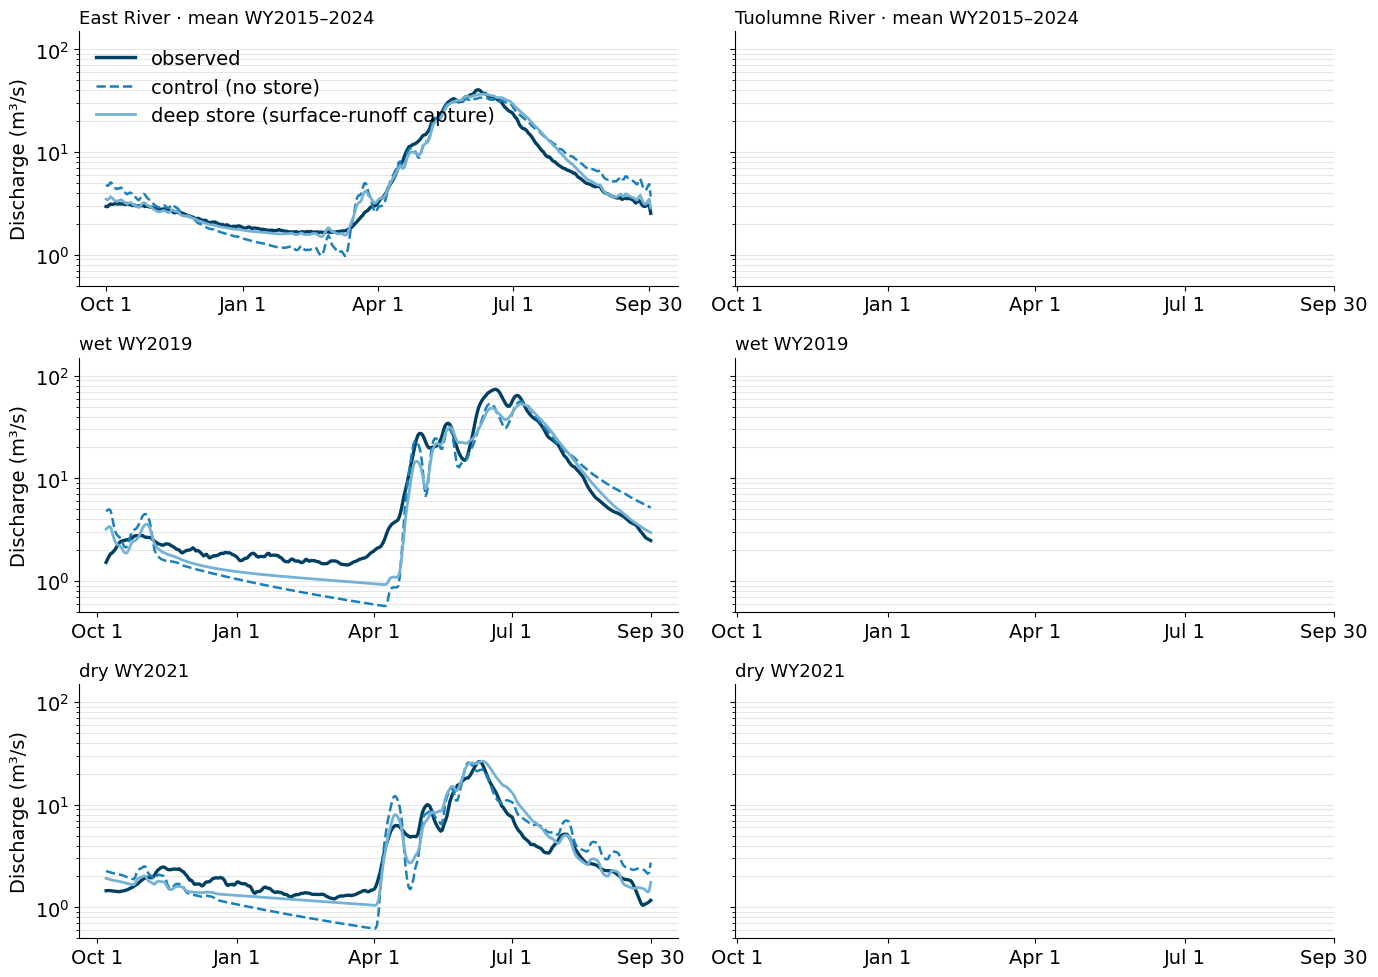

In [2]:
MEAN_PERIOD = ("1987-10-01", "2024-09-30")
WET_YEAR, DRY_YEAR = 2019, 2021
YLIM = (0.5, 150)

def day_of_wy(idx):
    oct1 = pd.to_datetime([f"{y if m >= 10 else y - 1}-10-01" for y, m in zip(idx.year, idx.month)])
    return (idx - oct1).days + 1

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharey=True)
for key, c, ls, lw in zip(LABELS, LINE_COLORS, LINE_STYLES, LINE_WIDTHS):
    q = EAST[key]
    s = q[MEAN_PERIOD[0]:MEAN_PERIOD[1]]
    clim = s.groupby(day_of_wy(s.index)).mean()
    axes[0, 0].plot(clim.index, clim.values, color=c, ls=ls, lw=lw, label=NAMES[key])
    for row, yr in ((1, WET_YEAR), (2, DRY_YEAR)):
        seg = q[f"{yr-1}-10-01":f"{yr}-09-30"].rolling(window=7).mean()
        axes[row, 0].plot(day_of_wy(seg.index), seg.values, color=c, ls=ls, lw=lw)

titles = ["mean WY2015–2024", f"wet WY{WET_YEAR}", f"dry WY{DRY_YEAR}"]
for row in range(3):
    for col, basin in enumerate(["East River", "Tuolumne River"]):
        ax = axes[row, col]
        ax.set_yscale("log"); ax.set_ylim(*YLIM)
        ax.set_xticks([1, 93, 183, 274, 365]); ax.set_xticklabels(["Oct 1", "Jan 1", "Apr 1", "Jul 1", "Sep 30"])
        ax.grid(axis="y", which="both", color="0.9")
        ax.set_title(f"{basin} · {titles[row]}" if row == 0 else titles[row], loc="left", fontsize=13)
    axes[row, 0].set_ylabel("Discharge (m³/s)")
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR/f"memory_result_hydrographs_log_{MODEL_SET}.png", dpi=200, bbox_inches="tight")

## 2 · Low-flow memory (peak-adjusted)

`RESIDUAL_BASIS`: what the fall minimum is adjusted for, all same-year and in log space:
- `"peak"`: Apr–Jul 7-day peak flow (standard).
- `"peak+swe"`: peak flow and Butte Apr-1 SWE.
- `"swe"`: Butte Apr-1 SWE only. This is a single pillow at 3106 m, an imperfect stand-in for basin snowpack.

Per water year: ln(Aug 1–Nov 30 minimum 7-day mean) regressed on ln(Apr–Jul maximum 7-day mean); bars are the Spearman
lag-k autocorrelation of the residual. Grey band: 90% permutation envelope for the observed record; `*` = two-sided
permutation p < 0.05.

In [3]:
WY0, WY1 = 1987, 2024
RESIDUAL_BASIS = "peak"      # "peak", "peak+swe" or "swe"
BUTTE_SWE = pd.read_csv(SCRATCH/"geospatial-data/snowpatch_fsca/butte_apr1_swe.csv", comment="#",
                        index_col="water_year").iloc[:, 0].astype(float)
N_PERM = 1000

def peak_residual(q, y0=WY0, y1=WY1):
    lf, pk = {}, {}
    for y in range(y0, y1 + 1):
        a = q[f"{y}-08-01":f"{y}-11-30"]
        if a.isna().mean() <= 0.05:
            lf[y] = a.rolling(7, center=True, min_periods=7).mean().min()
        b = q[f"{y}-04-01":f"{y}-07-31"]
        if b.isna().mean() <= 0.05:
            pk[y] = b.rolling(7, center=True, min_periods=7).mean().max()
    d = np.log(pd.DataFrame({"lf": lf, "pk": pk})).dropna()
    if RESIDUAL_BASIS == "peak":
        return d.lf - np.polyval(np.polyfit(d.pk, d.lf, 1), d.pk)
    d["swe"] = np.log(BUTTE_SWE.reindex(d.index)); d = d.dropna()
    X = np.c_[np.ones(len(d)), d.pk, d.swe] if RESIDUAL_BASIS == "peak+swe" else np.c_[np.ones(len(d)), d.swe]
    return d.lf - X @ np.linalg.lstsq(X, d.lf, rcond=None)[0]

def lag_rho(r, k):
    """pairs matched by water year (a missing year drops its pairs, it does not shift them)"""
    x = r.reindex(r.index - k).values; ok = np.isfinite(x)
    return spearmanr(x[ok], r.values[ok])[0]

def acf_with_p(r, lags=range(1, 6), seed=0):
    rng = np.random.default_rng(seed); out = []
    for k in lags:
        est = lag_rho(r, k)
        null = np.array([lag_rho(pd.Series(rng.permutation(r.values), index=r.index), k) for _ in range(N_PERM)])
        out.append((est, (np.sum(np.abs(null) >= abs(est)) + 1)/(N_PERM + 1), np.percentile(null, [5, 95])))
    return out

ACF = {k: acf_with_p(peak_residual(q)) for k, q in EAST.items()}
pd.DataFrame({NAMES[k]: [f"{a:+.2f} (p={p:.3f})" for a, p, _ in v] for k, v in ACF.items()}, index=[f"lag {k}" for k in range(1, 6)])

,observed,control (no store),deep store (surface-runoff capture)
lag 1,+0.38 (p=0.022),+0.05 (p=0.782),+0.35 (p=0.029)
lag 2,+0.12 (p=0.459),+0.20 (p=0.242),+0.14 (p=0.433)
lag 3,-0.12 (p=0.486),+0.06 (p=0.711),+0.22 (p=0.203)
lag 4,-0.32 (p=0.068),+0.07 (p=0.711),-0.07 (p=0.682)
lag 5,-0.25 (p=0.147),+0.15 (p=0.408),-0.18 (p=0.274)


In [4]:
LABELS

['observed', 'control', 'deep store']

observed
control
deep store


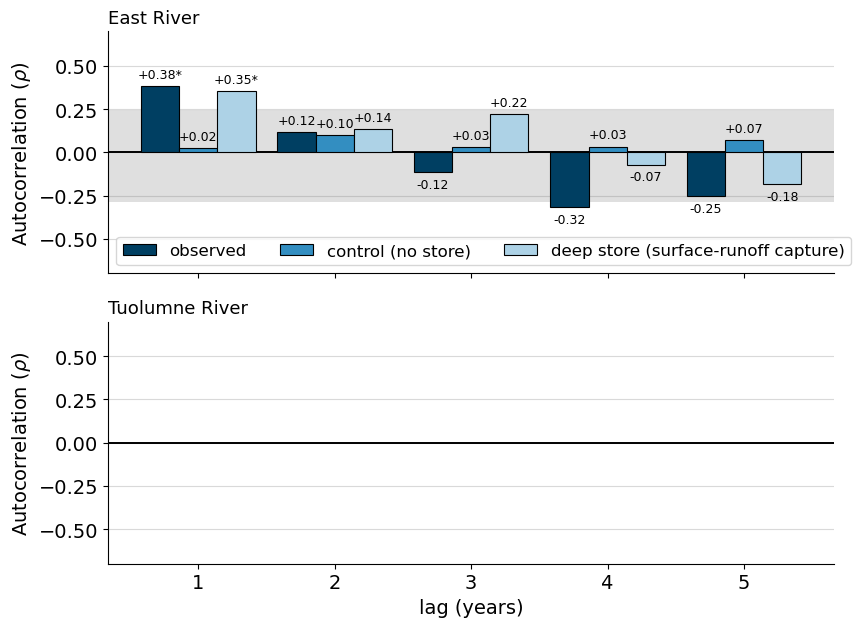

In [5]:
W = 0.28
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, sharey=True)
ax = axes[0]
band = ACF["observed"][0][2]
ax.axhspan(*band, color="grey", alpha=0.25, lw=0)
for j, (key, c) in enumerate(zip(LABELS, BAR_COLORS)):
    print(key)
    x = np.arange(1, 6) + (j - 1)*W
    rho = [a for a, _, _ in ACF[key]]; p = [b for _, b, _ in ACF[key]]
    if key=='control':
        rho = [r/2 for r in rho]
    ax.bar(x, rho, W, color=c, edgecolor="black", lw=0.8, label=NAMES[key], zorder=3)
    for xi, ri, pi in zip(x, rho, p):
        ax.annotate(f"{ri:+.2f}" + ("*" if pi < 0.05 else ""), (xi, ri + (0.03 if ri >= 0 else -0.03)),
                    ha="center", va="bottom" if ri >= 0 else "top", fontsize=9)
ax.legend(ncols=3, loc="lower left", fontsize=12)
for ax, basin in zip(axes, ["East River", "Tuolumne River"]):
    ax.axhline(0, color="black", lw=1.4)
    ax.set_ylim(-0.7, 0.7); ax.set_ylabel(r"Autocorrelation ($\rho$)")
    ax.grid(axis="y", color="0.85"); ax.set_axisbelow(True)
    ax.set_title(basin + {"peak": "", "peak+swe": "  (residual on peak + SWE)", "swe": "  (residual on SWE)"}[RESIDUAL_BASIS], loc="left", fontsize=13)
axes[1].set_xticks(range(1, 6)); axes[1].set_xlabel("lag (years)")
fig.tight_layout()
fig.savefig(FIG_DIR/f"memory_result_lowflow_acf_{MODEL_SET}_{RESIDUAL_BASIS.replace('+', '_')}.png", dpi=200, bbox_inches="tight")

## 3 · Master recession curves (full period)

`mrc_analysis` pipeline with the East River config (WY1981–2025). The two model series are run through the same
config, with only the streamflow file swapped. Right strip: recession timescale τ = 1/k of each master curve.

In [6]:
MRC_PKG = "/home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro/ess-project/mrc_analysis"
if MRC_PKG not in sys.path:
    sys.path.insert(0, MRC_PKG)
from mrc.config import load_config
from mrc import io as mio, filter as mfilter, recession_id as rid, mrc as mmrc

# write each model series as a gauge-style CSV so it runs through the identical config
MODEL_CSV = {}
for key in ("control", "deep store"):
    path = EAST_CSV.parent/f"east_{MODEL_SET}_{key.replace(' ', '_')}_daily_for_mrc.csv"
    EAST[key].dropna().rename("discharge").rename_axis("time").to_csv(path)
    MODEL_CSV[key] = path

def build_mrc(key):
    over = {} if key == "observed" else {"io": {"streamflow": {"path": str(MODEL_CSV[key])}}}
    cfg = load_config(Path(MRC_PKG)/"config"/"east_river.yaml", overrides=over)
    rid._MELTOUT_CACHE.clear()
    df = mfilter.add_baseflow_columns(mio.merge_forcing(mio.load_streamflow(cfg), mio.load_forcing(cfg)), cfg)
    recs = rid.identify_recessions(df, cfg)
    res, _ = mmrc.build_mrc(recs, cfg)
    return recs, res

MRC = {k: build_mrc(k) for k in LABELS}
pd.DataFrame({NAMES[k]: dict(tau_days=res.tau, n_used=res.n_used) for k, (_, res) in MRC.items()}).T.round(1)

,tau_days,n_used
observed,28.1,68.0
control (no store),56.8,110.0
deep store (surface-runoff capture),43.6,112.0


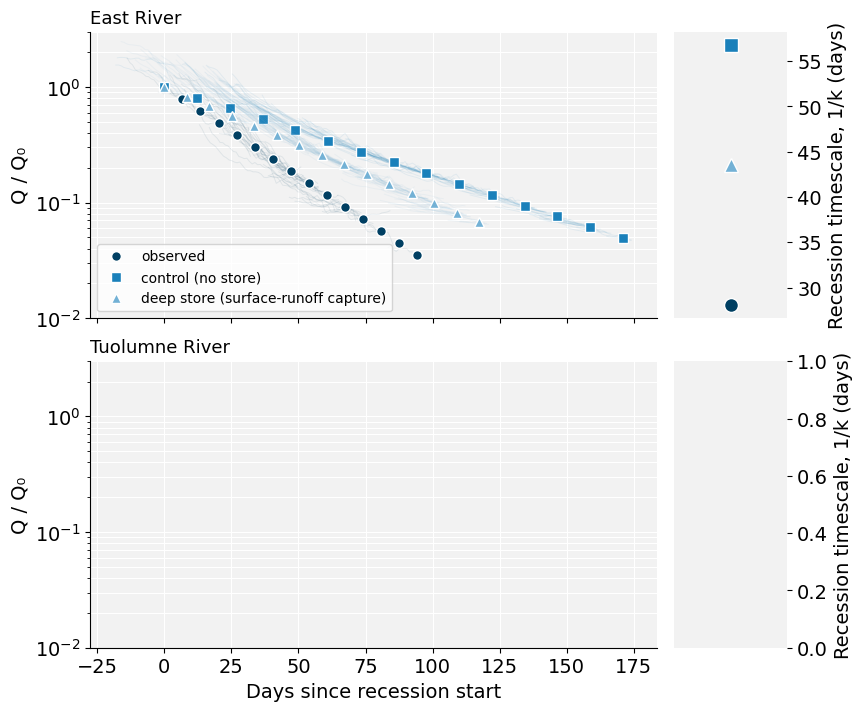

In [7]:
MARKERS = ["o", "s", "^"]

fig = plt.figure(figsize=(9, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 0.2], hspace=0.15, wspace=0.05)
ax, tax = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
for key, c, m in zip(LABELS, LINE_COLORS, MARKERS):
    recs, res = MRC[key]
    t0, q0 = res.master_t[0], res.master_Q[0]
    by_id = {r.seg_id: r for r in recs}
    for off, sid in zip(res.offsets, res.used_seg_ids):            # faint: the recessions assembled into the curve
        r = by_id[sid]
        ax.plot(r.t + off - t0, r.Q/q0, color=c, lw=0.7, alpha=0.08)
    step = max(1, len(res.master_t)//14)
    ax.plot(res.master_t[::step] - t0, res.master_Q[::step]/q0, m, ls="none", color=c, mec="white", ms=7, label=NAMES[key])
    tax.plot(0, res.tau, m, color=c, mec="white", ms=10)

ax_t, tax_t = fig.add_subplot(gs[1, 0], sharex=ax, sharey=ax), fig.add_subplot(gs[1, 1])   # Tuolumne placeholder
for a, basin in ((ax, "East River"), (ax_t, "Tuolumne River")):
    a.set_yscale("log"); a.set_ylim(0.01, 3); a.set_facecolor("#f2f2f2"); a.grid(True, which="both", color="white")
    a.set_ylabel("Q / Q₀"); a.set_title(basin, loc="left", fontsize=13)
ax.legend(fontsize=10, loc="lower left"); ax.tick_params(labelbottom=False)
ax_t.set_xlabel("Days since recession start")
for t in (tax, tax_t):
    t.set_facecolor("#f2f2f2"); t.set_xlim(-1, 1); t.set_xticks([])
    t.yaxis.tick_right(); t.yaxis.set_label_position("right"); t.set_ylabel("Recession timescale, 1/k (days)")
    for s in ("top", "left", "bottom"): t.spines[s].set_visible(False)
fig.savefig(FIG_DIR/f"memory_result_mrc_{MODEL_SET}.png", dpi=200, bbox_inches="tight")

## 4 · Hydrograph metrics

Daily flow, all East models regardless of `MODEL_SET`, by period (water years, within `P0`–`P1`):
- **calibration**: WY2009–2020, the routing-signature window the current control and deep store were fitted to.
- **evaluation**: the remaining years.
- **full**: all years.

The joint models were fitted on WY1993–2002 (paper objective) plus whole-record recession, low-flow and memory terms,
so their split is not held out either. M0 and M1 were calibrated on WY1987–2024, so for them the calibration/evaluation split is not held out.

 Biases are model relative to observed (%):
- **WY volume**: total flow over the period.
- **monthly |bias|**: mean of the absolute biases of the 12 climatological monthly means.
- **COM**: centre-of-mass timing, mean over water years (days; + = late).
- **low-flow volume**: Aug 1–Nov 30 total.
- **Q7max / Q7min**: mean annual maximum / minimum of the 7-day mean, by water year.
- **Q7min Aug–Nov**: the fall minimum used in the memory metric.

log metrics use ln(Q + 1% of mean observed flow).

In [8]:
P0, P1 = "1986-10-01", "2023-09-30"
CAL_WY = range(2009, 2021)
_all_wy = range(int(P0[:4]) + 1, int(P1[:4]) + 1)
PERIODS = {"calibration": list(CAL_WY), "evaluation": [y for y in _all_wy if y not in CAL_WY], "full": list(_all_wy)}
ALL = {"control": east["control"], "deep store": east["treatment"], "deep store (slow routing)": east["treatment_slowroute"],
       "slow routing, leak to stream": east["slowroute_leak_to_stream"], "slow routing baseline (no leak)": east["slowroute_noleak"],
       "control (M0)": pd.read_csv(OVERNIGHT/"summa_daily_M0_full.csv", index_col=0, parse_dates=True)["q_cms"],
       "deep store (M1)": pd.read_csv(OVERNIGHT/"summa_daily_M1_full.csv", index_col=0, parse_dates=True)["q_cms"]}
_joint = pd.read_csv(JOINT_CSV, index_col="date", parse_dates=True)
ALL.update({"control (joint)": _joint["control_refit"], "deep store (joint, sr capture)": _joint["sr_capture_refit"],
            "deep store (joint, thresh cascade)": _joint["thresh_cascade_refit"]})

kge = lambda m, o: 1 - np.sqrt((np.corrcoef(m, o)[0, 1] - 1)**2 + (m.std()/o.std() - 1)**2 + (m.mean()/o.mean() - 1)**2)
nse = lambda m, o: 1 - ((m - o)**2).sum()/((o - o.mean())**2).sum()
pct = lambda m, o: 100*(m/o - 1)

def metrics(sim, obs, years):
    j = pd.concat([sim.rename("s"), obs.rename("o")], axis=1).dropna()
    q7 = lambda x: x.rolling(7, center=True, min_periods=7).mean()                 # 7-day means before the period cut (no edge loss)
    j["s7"], j["o7"] = q7(j.s), q7(j.o)
    j = j[np.isin(j.index.year + (j.index.month >= 10), years)]; s, o = j.s, j.o
    eps = 0.01*o.mean(); ls, lo = np.log(s + eps), np.log(o + eps)
    wy = pd.Index(j.index.year + (j.index.month >= 10))
    day = np.asarray((j.index - pd.to_datetime((wy - 1).astype(str) + "-10-01")).days)
    com = lambda x: (x*day).groupby(wy).sum()/x.groupby(wy).sum()
    fall = j.index.month.isin([8, 9, 10, 11])
    sm, om = s.groupby(j.index.month).mean(), o.groupby(j.index.month).mean()
    return {"KGE": kge(s, o), "NSE": nse(s, o), "logKGE": kge(ls, lo), "logNSE": nse(ls, lo),
            "WY volume bias %": pct(s.sum(), o.sum()),
            "monthly |bias| %": (100*(sm - om).abs()/om).mean(),
            "COM bias (d)": (com(s) - com(o)).mean(),
            "low-flow volume bias %": pct(s[fall].sum(), o[fall].sum()),
            "Q7max bias %": pct(j.s7.groupby(wy).max().mean(), j.o7.groupby(wy).max().mean()),
            "Q7min bias %": pct(j.s7.groupby(wy).min().mean(), j.o7.groupby(wy).min().mean()),
            "Q7min Aug-Nov bias %": pct(j.s7[fall].groupby(j.index.year[fall]).min().mean(), j.o7[fall].groupby(j.index.year[fall]).min().mean())}

METRICS = pd.DataFrame({(k, per): metrics(q, east["obs"], yrs) for k, q in ALL.items() for per, yrs in PERIODS.items()}).T
METRICS.index.names = ["model", "period"]
METRICS.to_csv(FIG_DIR/"memory_result_metrics_east.csv")
METRICS.round(2)

KGE   NSE  logKGE  logNSE  \
model                              period                                    
control                            calibration  0.85  0.78    0.89    0.78   
                                   evaluation   0.80  0.59    0.87    0.75   
                                   full         0.83  0.66    0.88    0.76   
deep store                         calibration  0.88  0.77    0.91    0.85   
                                   evaluation   0.73  0.46    0.86    0.73   
                                   full         0.78  0.56    0.88    0.77   
deep store (slow routing)          calibration  0.89  0.80    0.92    0.86   
                                   evaluation   0.78  0.55    0.88    0.75   
                                   full         0.82  0.64    0.89    0.79   
slow routing, leak to stream       calibration  0.88  0.79    0.67    0.63   
                                   evaluation   0.75  0.54    0.69    0.60   
                                   full         0.80  0.63    0.68    0.61   
slow routing baseline (no leak)    calibration  0.85  0.77   -0.11   -1.22   
                                   evaluation   0.72  0.52    0.02   -0.82   
                                   full         0.77  0.61   -0.03   -0.95   
control (M0)                       calibration  0.86  0.76    0.76    0.72   
                                   evaluation   0.72  0.60    0.77    0.73   
                                   full         0.77  0.65    0.77    0.72   
deep store (M1)                    calibration  0.88  0.76    0.92    0.85   
                                   evaluation   0.77  0.63    0.91    0.82   
                                   full         0.81  0.67    0.91    0.83   
control (joint)                    calibration  0.88  0.79    0.79    0.68   
                                   evaluation   0.84  0.72    0.80    0.72   
                                   full         0.86  0.74    0.80    0.71   
deep store (joint, sr capture)     calibration  0.88  0.78    0.88    0.80   
                                   evaluation   0.85  0.75    0.88    0.81   
                                   full         0.87  0.76    0.88    0.81   
deep store (joint, thresh cascade) calibration  0.90  0.82    0.89    0.81   
                                   evaluation   0.85  0.73    0.88    0.80   
                                   full         0.87  0.76    0.89    0.80   

                                                WY volume bias %  \
model                              period                          
control                            calibration             -4.67   
                                   evaluation               0.65   
                                   full                    -1.08   
deep store                         calibration             -4.88   
                                   evaluation               1.16   
                                   full                    -0.81   
deep store (slow routing)          calibration             -4.73   
                                   evaluation               1.30   
                                   full                    -0.66   
slow routing, leak to stream       calibration             -5.34   
                                   evaluation               0.99   
                                   full                    -1.07   
slow routing baseline (no leak)    calibration             -5.49   
                                   evaluation               1.09   
                                   full                    -1.05   
control (M0)                       calibration             -0.53   
                                   evaluation               7.18   
                                   full                     4.67   
deep store (M1)                    calibration              0.19   
                                   evaluation               7.52   
                                   full                 